In [1]:
import os
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, precision_score, recall_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification


In [2]:
DATA_PATH = "../data/processed/jigsaw_clean.parquet"
PROBES_PATH = "../data/probe_sentences.csv"
BLOCKLIST_PATH = "../data/blocklist/ldnoobw_en.txt"
BERT_DIR = "../models/soft_idw_lr2e-05_ep2/final"
TFIDF_DIR = "../models/tfidf_lr"

In [3]:
MAIN_IDENTITIES = [
    "male", "female", "homosexual_gay_or_lesbian", "christian", "jewish",
    "muslim", "black", "white", "psychiatric_or_mental_illness",
]

In [4]:

MODELS = ["Blocklist", "TF-IDF + LR", "DistilBERT"]
CMAPS = ["Greys", "Greens", "Blues"]
COLORS = ["#9AA3AB", "#2E6B4F", "#123B5C"]  # poster palette

# 1. Load Data

The three models are compared on the same test set , which was not used for any decision:

1. Blocklist
2. TF-IDF + LR
3. DistilBERT: soft labels + identity weights (epoch 2)


In [5]:
identities = pd.read_parquet(DATA_PATH, columns=["id", "split"] + MAIN_IDENTITIES)
identities = identities[identities["split"] == "test"].drop(columns="split")

blocklist = pd.read_parquet("../results/predictions/blocklist/test.parquet")
tfidf = pd.read_parquet("../results/predictions/tfidf/test.parquet")
bert = pd.read_parquet("../results/predictions/soft_idw_lr2e-05_ep2/test.parquet")

# pred = decision (1 = toxic), score = continuous output used for the AUC
raw = {
    "Blocklist": blocklist.assign(pred=blocklist["blocked"], score=blocklist["score"]),
    "TF-IDF + LR": tfidf.assign(score=tfidf["prob_toxic"]),
    "DistilBERT": bert.assign(pred=(bert["prob_toxic"] >= 0.5).astype(int), score=bert["prob_toxic"]),
}
preds = {name: identities.merge(p[["id", "label", "pred", "score"]], on="id", validate="1:1")
         for name, p in raw.items()}

for name, p in preds.items():
    print(f"{name}: {len(p):,} comments, {p['label'].mean() * 100:.2f}% toxic, {p['pred'].mean() * 100:.2f}% marked as toxic")

# the three files must contain the same comments with the same labels
labels = [p.set_index("id")["label"].sort_index() for p in preds.values()]
print("Same comments and labels:", all(l.equals(labels[0]) for l in labels))

Blocklist: 177,635 comments, 7.98% toxic, 2.88% marked as toxic
TF-IDF + LR: 177,635 comments, 7.98% toxic, 5.80% marked as toxic
DistilBERT: 177,635 comments, 7.98% toxic, 5.82% marked as toxic
Same comments and labels: True


# 2. Confusion Matrix

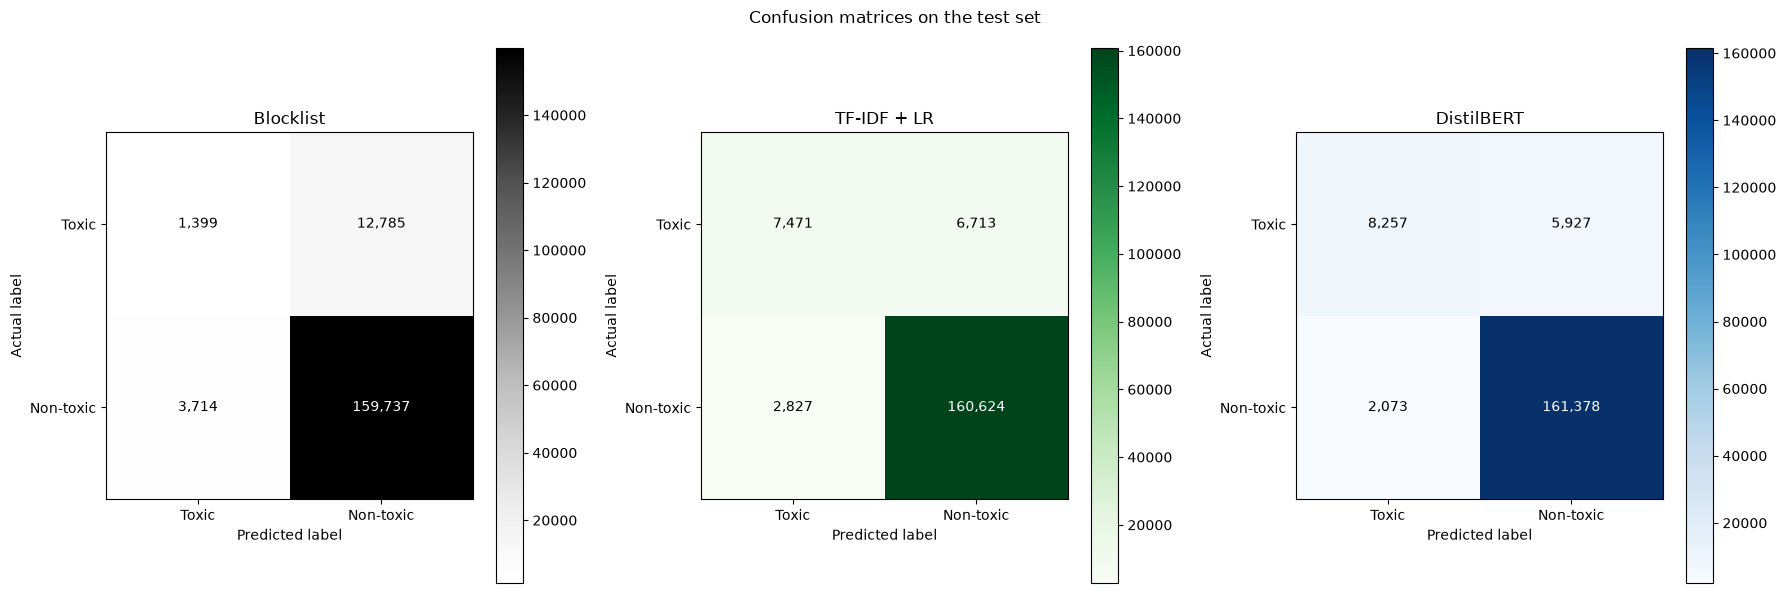

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
order = [1, 0]  # toxic first

for ax, cmap, (name, p) in zip(axes, CMAPS, preds.items()):
    counts = pd.crosstab(p["label"], p["pred"]).reindex(index=order, columns=order, fill_value=0)
    im = ax.imshow(counts, cmap=cmap)
    fig.colorbar(im, ax=ax)
    for (i, j), n in np.ndenumerate(counts.values):
        ax.text(j, i, f"{n:,}", ha="center", va="center", color="white" if n > counts.values.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Toxic", "Non-toxic"])
    ax.set_yticks([0, 1], ["Toxic", "Non-toxic"])
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.set_title(name)

fig.suptitle("Confusion matrices on the test set")
plt.tight_layout()
plt.show()

**Conclusions:**

- **Blocklist:** it detects only 10% of the toxic comments. most toxic comments use common insults that are not in the list.
- **TF-IDF + LR** and **DistilBERT** mark almost the same number of comments as toxic, but DistilBERT gets more of them righ.  ore toxic comments detected and fewer non-toxic comments blocked.

# 3. Metrics on the Test Set

- Precision, recall and F1 use the decision of each model
-  ROC AUC and PR-AUC use the continuous output: the probability for TF-ID and DistilBERT


In [7]:
rows = {}
for name, p in preds.items():
    y_true, y_pred = p["label"], p["pred"]
    rows[name] = {
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc auc": roc_auc_score(y_true, p["score"]),
        "pr auc": average_precision_score(y_true, p["score"]),
        "fpr": ((y_pred == 1) & (y_true == 0)).sum() / (y_true == 0).sum(),
    }

metrics = pd.DataFrame(rows).T.round(3)
metrics

,precision,recall,f1,roc auc,pr auc,fpr
Blocklist,0.274,0.099,0.145,0.538,0.099,0.023
TF-IDF + LR,0.725,0.527,0.610,0.932,0.687,0.017
DistilBERT,0.799,0.582,0.674,0.964,0.782,0.013


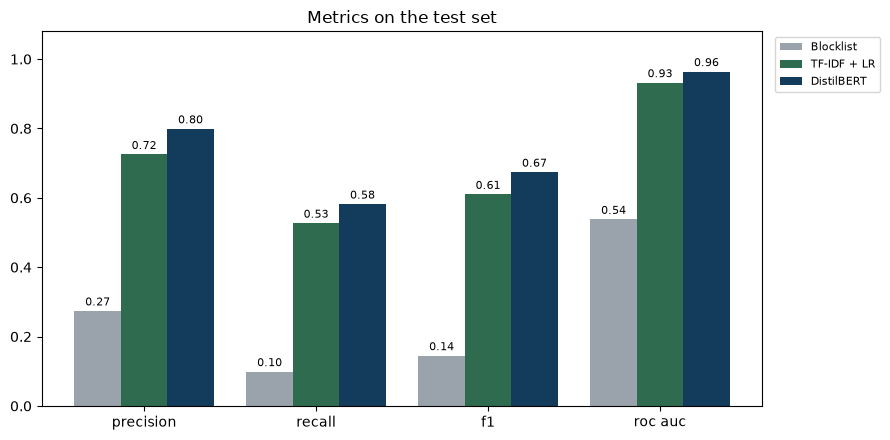

In [8]:
cols = ["precision", "recall", "f1", "roc auc"]
x = np.arange(len(cols))
width = 0.27

fig, ax = plt.subplots(figsize=(9, 4.5))
for k, (name, color) in enumerate(zip(MODELS, COLORS)):
    bars = ax.bar(x + (k - 1) * width, metrics.loc[name, cols], width, color=color, label=name)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in metrics.loc[name, cols]], padding=2, fontsize=8)

ax.set_xticks(x, cols)
ax.set_ylim(0, 1.08)
ax.set_title("Metrics on the test set")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## 3.1 Precision-Recall Curves

Each point of a curve is a different threshold. 
- Lowering the threshold marks more comments as toxic, so recall goes up and precision goes down. 

- A curve that is higher and further to the right is better.

*Note*:The marker on each curve is the threshold used in this notebook (0.5).

 The blocklist has no probability, only a fixed rule so it is drawn as a single point instead of a curve. 

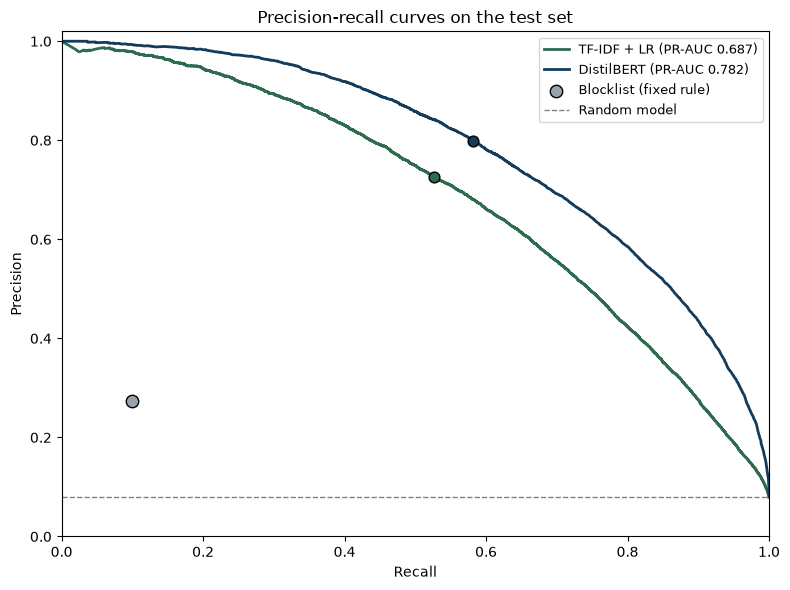

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, color in zip(MODELS[1:], COLORS[1:]):
    p = preds[name]
    precision, recall, _ = precision_recall_curve(p["label"], p["score"])
    ax.plot(recall, precision, color=color, linewidth=2, label=f"{name} (PR-AUC {metrics.loc[name, 'pr auc']:.3f})")
    ax.scatter(metrics.loc[name, "recall"], metrics.loc[name, "precision"], color=color, s=60, edgecolor="black", zorder=3)

# the blocklist has no probability, only a fixed rule: one operating point
ax.scatter(metrics.loc["Blocklist", "recall"], metrics.loc["Blocklist", "precision"], color=COLORS[0], s=80,
           edgecolor="black", zorder=3, label="Blocklist (fixed rule)")

ax.axhline(preds["DistilBERT"]["label"].mean(), color="gray", linestyle="--", linewidth=1, label="Random model")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_title("Precision-recall curves on the test set")
ax.legend(fontsize=9, loc="upper right")
plt.tight_layout()
plt.show()

**Conclusions:**

- **DistilBERT** is the best model on every metric
- **Recall** is still the weak point: DistilBERT misses 42% of the toxic comments at threshold 0.5.

- The precision-recall curve of **DistilBERT** is above TF-IDF at every threshold: for the same recall, it always blocks fewer non-toxic comments 

# 4. Performance by Identity Subgroup

For each model and each of the 9 identity subgroups (identity value >= 0.5):

- **acc toxic**: share of toxic comments that are detected, $TP / (TP + FN)$.
- **acc non-toxic**: share of non-toxic comments that are let through, $TN / (TN + FP)$.
- **fpr**: share of non-toxic comments wrongly marked as toxic, $1 - \text{acc non-toxic}$.

In [10]:
def group_metrics(p, mask):
    y_true, y_pred = p.loc[mask, "label"], p.loc[mask, "pred"]
    acc_non_toxic = ((y_pred == 0) & (y_true == 0)).sum() / (y_true == 0).sum() * 100
    return {
        "acc toxic": ((y_pred == 1) & (y_true == 1)).sum() / (y_true == 1).sum() * 100,
        "acc non-toxic": acc_non_toxic,
        "fpr": 100 - acc_non_toxic,
    }

tables = {}
for name, p in preds.items():
    rows = {"all (test)": group_metrics(p, pd.Series(True, index=p.index))}
    for group in MAIN_IDENTITIES:
        rows[group] = group_metrics(p, p[group] >= 0.5)
    tables[name] = pd.DataFrame(rows).T

by_group = pd.concat(tables, axis=1).round(1)

sizes = preds["DistilBERT"]
by_group.insert(0, ("comments", ""), [len(sizes)] + [int((sizes[g] >= 0.5).sum()) for g in MAIN_IDENTITIES])
by_group.insert(1, ("toxic", ""), [int(sizes["label"].sum())] + [int(sizes.loc[sizes[g] >= 0.5, "label"].sum()) for g in MAIN_IDENTITIES])
by_group

comments  toxic Blocklist                      \
                                              acc toxic acc non-toxic   fpr   
all (test)                      177635  14184       9.9          97.7   2.3   
male                              4382    672      22.8          88.4  11.6   
female                            5188    702      29.2          85.1  14.9   
homosexual_gay_or_lesbian         1071    307      27.4          77.2  22.8   
christian                         3888    406      16.5          92.8   7.2   
jewish                             686    127       7.9          95.0   5.0   
muslim                            2017    481       6.2          96.7   3.3   
black                             1478    474       9.5          93.7   6.3   
white                             2436    696       8.0          95.9   4.1   
psychiatric_or_mental_illness      445     98       3.1          96.3   3.7   

                              TF-IDF + LR                     DistilBERT  \
                                acc toxic acc non-toxic   fpr  acc toxic   
all (test)                           52.7          98.3   1.7       58.2   
male                                 47.8          94.9   5.1       47.8   
female                               48.9          95.6   4.4       48.7   
homosexual_gay_or_lesbian            45.3          89.5  10.5       41.7   
christian                            43.8          97.6   2.4       38.4   
jewish                               48.8          93.2   6.8       35.4   
muslim                               44.9          91.7   8.3       45.1   
black                                48.3          87.1  12.9       41.1   
white                                49.1          89.6  10.4       42.2   
psychiatric_or_mental_illness        57.1          93.1   6.9       62.2   

                                                  
                              acc non-toxic  fpr  
all (test)                             98.7  1.3  
male                                   97.7  2.3  
female                                 98.1  1.9  
homosexual_gay_or_lesbian              94.4  5.6  
christian                              98.4  1.6  
jewish                                 97.1  2.9  
muslim                                 97.0  3.0  
black                                  94.6  5.4  
white                                  95.7  4.3  
psychiatric_or_mental_illness          96.8  3.2

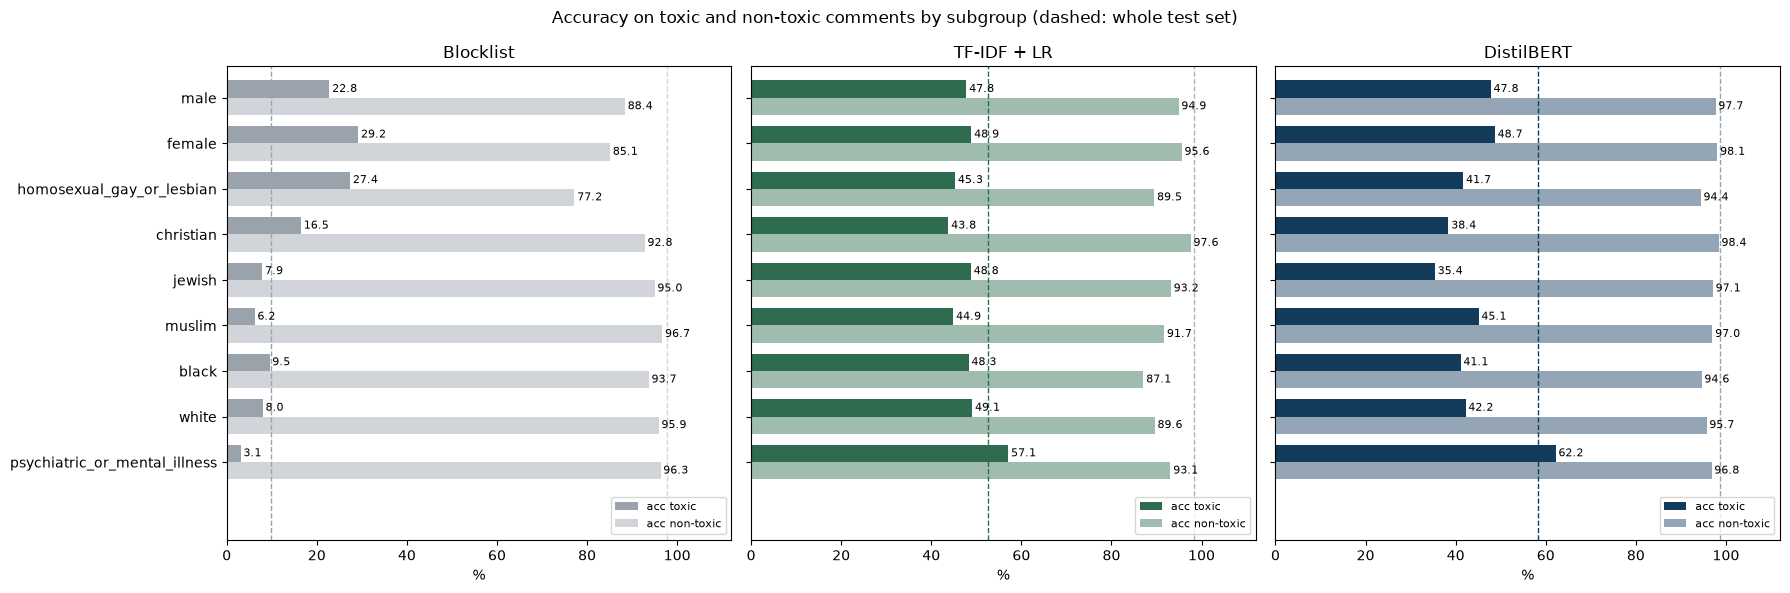

In [11]:
groups = MAIN_IDENTITIES
y = np.arange(len(groups))
height = 0.38

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, name, color in zip(axes, MODELS, COLORS):
    for k, (metric, alpha) in enumerate([("acc toxic", 1.0), ("acc non-toxic", 0.45)]):
        values = by_group.loc[groups, (name, metric)]
        bars = ax.barh(y + k * height, values, height, color=color, alpha=alpha, label=metric)
        ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], padding=2, fontsize=8)
        ax.axvline(by_group.loc["all (test)", (name, metric)], color=color, alpha=alpha, linestyle="--", linewidth=1)
    ax.set_yticks(y + height / 2, groups)
    ax.set_ylim(len(groups) + 0.9, -0.5)  # top to bottom, with room for the legend
    ax.set_xlim(0, 112)
    ax.set_xlabel("%")
    ax.set_title(name)
    ax.legend(fontsize=8, loc="lower right")

fig.suptitle("Accuracy on toxic and non-toxic comments by subgroup (dashed: whole test set)")
plt.tight_layout()
plt.show()

**Conclusions:**

- **All three models** detect fewer toxic comments inside the identity subgroups than in the whole test set.
- **Blocklist:** its errors are in the gender and sexuality subgroups because the list is mostly sexual vocabulary.
- **TF-IDF + LR:** it blocks non-toxic comments that mention *black*  *homosexual_gay_or_lesbian*  and *white*. As we saw in `04_tfidf.ipynb` the identity words have positive coefficients, so mentioning the identity is enough to raise the probability.

- **DistilBERT:** it has the smallest gaps on non-toxic comments, but it detects few toxic comments in *jewish* , *christian* and *black*

# 5. Best Model on Non-Toxic Comments per Identity

For each subgroup, the model that wrongly marks the fewest non-toxic comments as toxic (lowest FPR). The accuracy on toxic comments is shown next to it, because a model can get a low FPR simply by marking very few comments as toxic.

In [12]:
fpr = by_group.xs("fpr", axis=1, level=1)[MODELS]
acc_toxic = by_group.xs("acc toxic", axis=1, level=1)[MODELS]

best = fpr.copy()
best["best model"] = fpr.idxmin(axis=1)
best["its acc toxic"] = [acc_toxic.loc[g, m] for g, m in best["best model"].items()]
best.columns = pd.MultiIndex.from_tuples([("fpr", m) for m in MODELS] + [("", "best model"), ("", "its acc toxic")])
best

fpr                                     \
                              Blocklist TF-IDF + LR DistilBERT  best model   
all (test)                          2.3         1.7        1.3  DistilBERT   
male                               11.6         5.1        2.3  DistilBERT   
female                             14.9         4.4        1.9  DistilBERT   
homosexual_gay_or_lesbian          22.8        10.5        5.6  DistilBERT   
christian                           7.2         2.4        1.6  DistilBERT   
jewish                              5.0         6.8        2.9  DistilBERT   
muslim                              3.3         8.3        3.0  DistilBERT   
black                               6.3        12.9        5.4  DistilBERT   
white                               4.1        10.4        4.3   Blocklist   
psychiatric_or_mental_illness       3.7         6.9        3.2  DistilBERT   

                                             
                              its acc toxic  
all (test)                             58.2  
male                                   47.8  
female                                 48.7  
homosexual_gay_or_lesbian              41.7  
christian                              38.4  
jewish                                 35.4  
muslim                                 45.1  
black                                  41.1  
white                                   8.0  
psychiatric_or_mental_illness          62.2

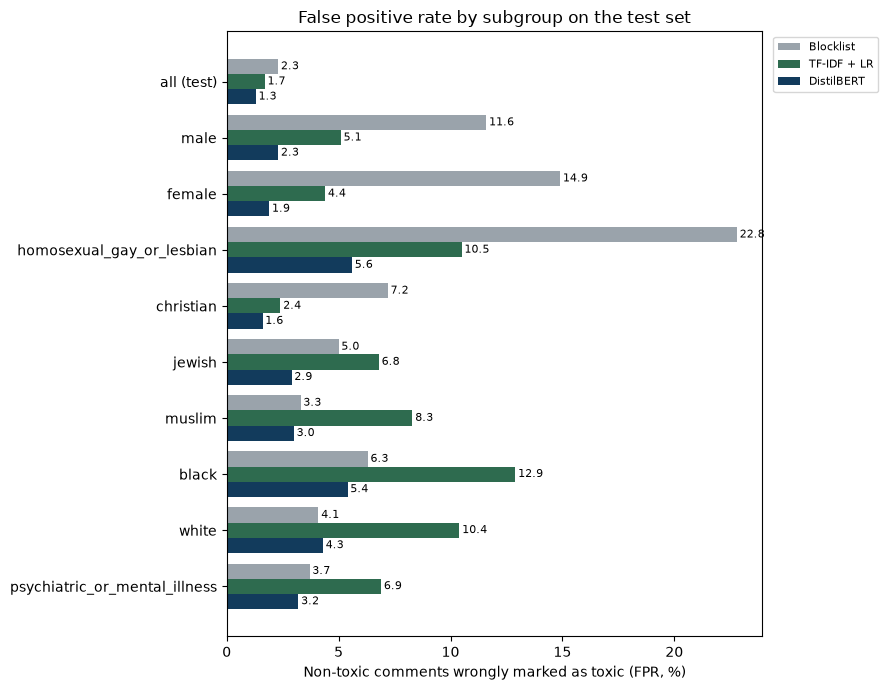

In [13]:
groups = ["all (test)"] + MAIN_IDENTITIES
y = np.arange(len(groups))
height = 0.27

fig, ax = plt.subplots(figsize=(9, 7))
for k, (name, color) in enumerate(zip(MODELS, COLORS)):
    values = fpr.loc[groups, name]
    bars = ax.barh(y + k * height, values, height, color=color, label=name)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], padding=2, fontsize=8)

ax.set_yticks(y + height, groups)
ax.invert_yaxis()
ax.set_xlabel("Non-toxic comments wrongly marked as toxic (FPR, %)")
ax.set_title("False positive rate by subgroup on the test set")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Conclusions:**

- **DistilBERT** has the lowest FPR in 8 of the 9 subgroups. 

- DistilBERT reduces the bias but does not remove it: the FPR for *homosexual_gay_or_lesbian* and *black* is about four times the overall FPR (1.3%).

# 6. Probe Sentences



In [ ]:
probes = pd.read_csv(PROBES_PATH).rename(columns={"expected": "target"})

# Blocklist
with open(BLOCKLIST_PATH) as f:
    entries = sorted({line.strip().lower() for line in f if line.strip()}, key=len, reverse=True)
pattern = re.compile(r"\b(?:" + "|".join(re.escape(w) for w in entries) + r")\b")
probes["Blocklist"] = probes["sentence"].str.lower().str.contains(pattern).astype(int)

# TF-IDF + LR 
if os.path.exists(TFIDF_DIR):
    vectorizer = joblib.load(f"{TFIDF_DIR}/vectorizer.joblib")
    clf = joblib.load(f"{TFIDF_DIR}/classifier.joblib")
    probes["TF-IDF + LR"] = (clf.predict_proba(vectorizer.transform(probes["sentence"]))[:, 1] >= 0.5).astype(int)
else:
    print(f"{TFIDF_DIR} not found: TF-IDF is left out of the probe sentences")

# DistilBERT
tokenizer = AutoTokenizer.from_pretrained(BERT_DIR)
model = AutoModelForSequenceClassification.from_pretrained(BERT_DIR).eval()
inputs = tokenizer(probes["sentence"].tolist(), padding=True, truncation=True, max_length=128, return_tensors="pt")
with torch.no_grad():
    probes["DistilBERT"] = (torch.softmax(model(**inputs).logits, dim=1)[:, 1] >= 0.5).int().numpy()

probe_models = [m for m in MODELS if m in probes]
probes[probe_models] = probes[probe_models].replace({1: "toxic", 0: "non-toxic"})

for category, group in probes.groupby("category", sort=False):
    print(f"\n{category}")
    display(group[["sentence", "target"] + probe_models].reset_index(drop=True))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


negation with insult


,sentence,target,Blocklist,TF-IDF + LR,DistilBERT
0,You are an idiot,toxic,non-toxic,toxic,toxic
1,You are not an idiot,non-toxic,non-toxic,toxic,toxic
2,You are stupid,toxic,non-toxic,toxic,toxic
3,You are not stupid,non-toxic,non-toxic,toxic,toxic



negation without insult


,sentence,target,Blocklist,TF-IDF + LR,DistilBERT
0,I hate gay people,toxic,non-toxic,toxic,toxic
1,I don't hate gay people,non-toxic,non-toxic,toxic,non-toxic
2,Black people are criminals,toxic,non-toxic,toxic,toxic
3,Black people are not criminals,non-toxic,non-toxic,toxic,non-toxic


...

,sentence,target,Blocklist,TF-IDF + LR,DistilBERT
0,Calling someone an idiot is not okay,non-toxic,non-toxic,toxic,toxic
1,Saying gay people are disgusting is hateful,non-toxic,non-toxic,toxic,toxic



profanity


,sentence,target,Blocklist,TF-IDF + LR,DistilBERT
0,This movie is fucking amazing,non-toxic,toxic,toxic,toxic
1,Holy shit what a great game,non-toxic,toxic,toxic,toxic



word order


,sentence,target,Blocklist,TF-IDF + LR,DistilBERT
0,You are an idiot and I am right,toxic,non-toxic,toxic,toxic
1,I am an idiot and you are right,non-toxic,non-toxic,toxic,toxic


In [ ]:
correct = pd.DataFrame({m: probes[m] == probes["target"] for m in probe_models}).assign(category=probes["category"])

hits = correct.groupby("category", sort=False).sum()
hits.insert(0, "sentences", probes.groupby("category", sort=False).size())
hits.loc["total"] = hits.sum()
hits

,sentences,Blocklist,TF-IDF + LR,DistilBERT
category,,,,
negation with insult,4,2,2,2
negation without insult,4,2,2,4
identity mention,8,6,6,7
counter-speech,2,2,0,0
profanity,2,0,0,0
word order,2,1,1,1
total,22,13,11,14


**Conclusions:**

- **DistilBERT** gets 14 of the 22 sentences right. 
    1. It understands negation when there is no insult ("I don't hate gay people")
    2.  Not when there is one ("You are not an idiot"), and it marks counter-speech, profanity used in a positive way and "I am an idiot and you are right" as toxic.
    3. It does not flag  some indentities as "I am a proud gay man", but it still flags "My neighbor is black".


# 7. Errors by Annotator Agreement

The test comments are split into three bands of `target` (share of annotators who marked the comment as toxic):

- **< 0.4**: clearly non-toxic, every error is a false positive.
- **0.4 - 0.6**: annotators disagree, both error types are possible.
- **> 0.6**: clearly toxic, every error is a false negative.



In [16]:
target = pd.read_parquet(DATA_PATH, columns=["id", "target"])
bands = ["< 0.4", "0.4 - 0.6", "> 0.6"]

rows = {}
for name, p in preds.items():
    p = p.merge(target, on="id")
    p["band"] = pd.cut(p["target"], [0, 0.4, 0.6, 1.01], labels=bands, right=False)
    p["error"] = p["pred"] != p["label"]
    rows[name] = p.groupby("band", observed=True)["error"].mean() * 100

errors_by_band = pd.DataFrame(rows).round(1)
errors_by_band.insert(0, "comments", p.groupby("band", observed=True).size())
errors_by_band


,comments,Blocklist,TF-IDF + LR,DistilBERT
band,,,,
< 0.4,157784,2.0,1.1,0.7
0.4 - 0.6,10458,46.3,40.9,38.2
> 0.6,9393,89.7,36.8,30.7


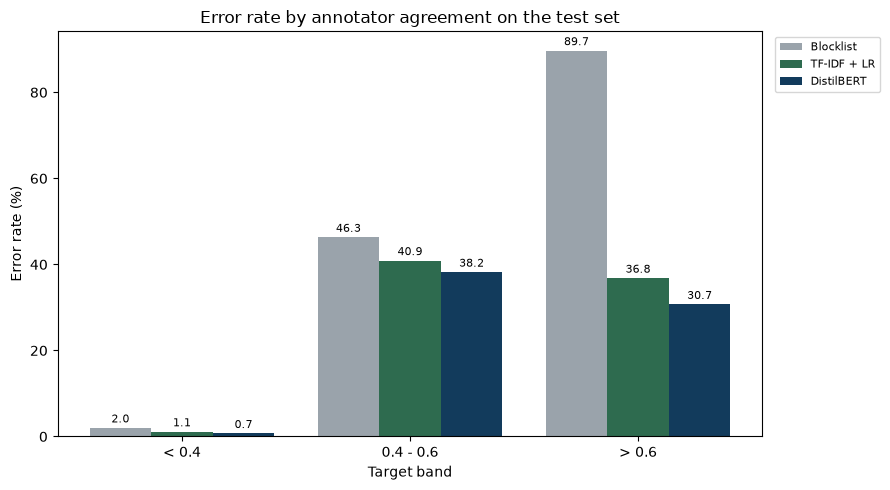

In [17]:
x = np.arange(len(bands))
width = 0.27

fig, ax = plt.subplots(figsize=(9, 5))
for k, (name, color) in enumerate(zip(MODELS, COLORS)):
    bars = ax.bar(x + (k - 1) * width, errors_by_band[name], width, color=color, label=name)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in errors_by_band[name]], padding=2, fontsize=8)

ax.set_xticks(x, bands)
ax.set_xlabel("Target band")
ax.set_ylabel("Error rate (%)")
ax.set_title("Error rate by annotator agreement on the test set")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()


## 7.1 Predicted Probability by Target Band

For TF-IDF and DistilBERT, distribution of the predicted probability of toxicity in each target band. 

A model that **captures annotator disagreement** should give low probabilities to clearly non-toxic comments, values near 0.5 to disputed comments and high probabilities to clearly toxic ones. The blocklist has no probability, so it is left out.


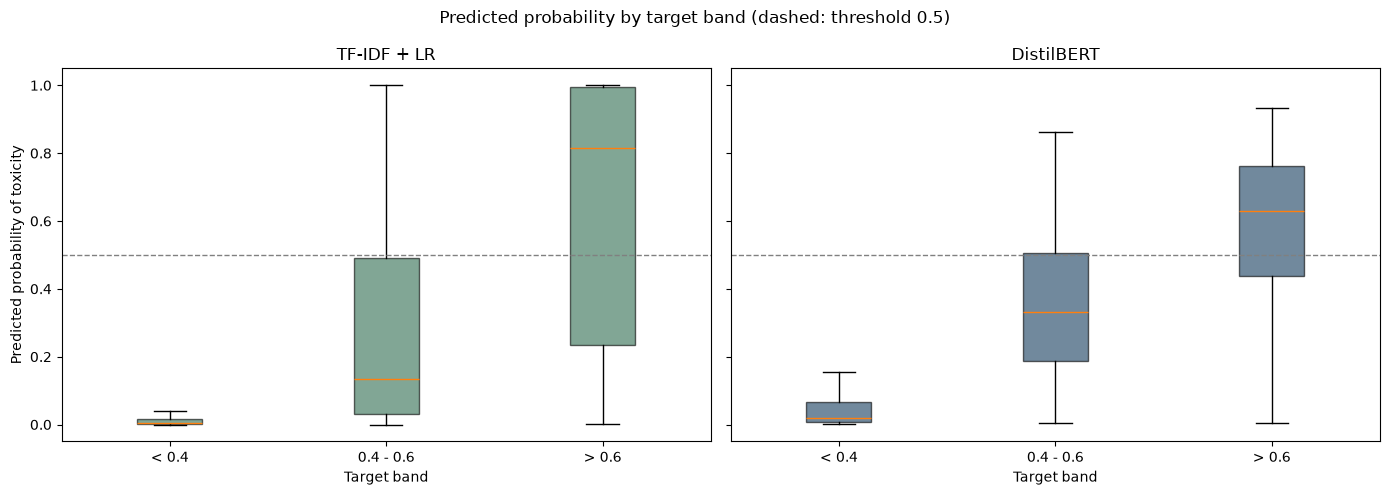

,TF-IDF + LR,DistilBERT
band,,
< 0.4,0.005,0.021
0.4 - 0.6,0.134,0.331
> 0.6,0.815,0.629


In [18]:
prob_models = ["TF-IDF + LR", "DistilBERT"]
banded = {}
for name in prob_models:
    p = preds[name].merge(target, on="id")
    p["band"] = pd.cut(p["target"], [0, 0.4, 0.6, 1.01], labels=bands, right=False)
    banded[name] = p

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, name, color in zip(axes, prob_models, COLORS[1:]):
    data = [banded[name].loc[banded[name]["band"] == b, "score"] for b in bands]
    box = ax.boxplot(data, tick_labels=bands, patch_artist=True, showfliers=False)
    for patch in box["boxes"]:
        patch.set_facecolor(color)
        patch.set_alpha(0.6)
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("Target band")
    ax.set_title(name)
axes[0].set_ylabel("Predicted probability of toxicity")

fig.suptitle("Predicted probability by target band (dashed: threshold 0.5)")
plt.tight_layout()
plt.show()

pd.DataFrame({name: banded[name].groupby("band", observed=True)["score"].median() for name in prob_models}).round(3)


## 7.2 Difference Between Predicted Probability and Target

For each comment, the predicted probability is compared with the target 

- **mean absolute difference**: how far the probability is from the annotators, $|p - \text{target}|$. Lower is better.
- **mean signed difference**: the direction of the difference, $p - \text{target}$. Negative means the model sees less toxicity than the annotators, positive means more.

DistilBERT was trained to predict the target (soft labels), while TF-IDF was trained on the binary label, so TF-IDF is expected to give more extreme probabilities.


In [20]:
rows = {}
for name in prob_models:
    p = banded[name].assign(diff=banded[name]["score"] - banded[name]["target"])
    by_band = p.groupby("band", observed=True)["diff"]
    rows[(name, "mean abs diff")] = by_band.apply(lambda d: d.abs().mean())
    rows[(name, "mean signed diff")] = by_band.mean()
    rows[(name, "mean abs diff")]["all"] = p["diff"].abs().mean()
    rows[(name, "mean signed diff")]["all"] = p["diff"].mean()

target_diff = pd.DataFrame(rows).round(3)
target_diff


TF-IDF + LR                     DistilBERT                 
          mean abs diff mean signed diff mean abs diff mean signed diff
band                                                                   
< 0.4             0.052           -0.013         0.056            0.016
0.4 - 0.6         0.325           -0.167         0.173           -0.109
> 0.6             0.316           -0.094         0.177           -0.143
all               0.082           -0.026         0.069           -0.000